# 04 — LSTM training, evaluation and SHAP

Run the project-paths cell first. Paths work from the project root or the notebooks folder.
Existing outputs are retained from the last run; historical path messages may show the former layout.
See [the project README](../README.md) for run order and current limitations.


In [ ]:
from pathlib import Path

# Locate the project whether the kernel starts in the root or notebooks/.
PROJECT_ROOT = next(
    (folder for folder in [Path.cwd(), *Path.cwd().parents]
     if (folder / 'requirements.txt').is_file()
     and (folder / 'notebooks').is_dir()
     and (folder / 'README.md').is_file()),
    None,
)
if PROJECT_ROOT is None:
    raise RuntimeError('Start this notebook from inside the Predictive maintenance for IoT project.')
RAW_DATA_DIR = PROJECT_ROOT / 'data' / 'raw' / 'cmapss'
PROCESSED_DATA_DIR = PROJECT_ROOT / 'data' / 'processed'
MODELS_DIR = PROJECT_ROOT / 'models'
FIGURES_DIR = PROJECT_ROOT / 'reports' / 'figures'
TABLES_DIR = PROJECT_ROOT / 'reports' / 'tables'
print(f'Project root: {PROJECT_ROOT}')


In [20]:
import numpy as np
import pandas as pd
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, LSTM, Dense, Dropout
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau, ModelCheckpoint
import matplotlib.pyplot as plt

In [21]:
from pathlib import Path
import json
import joblib

prepared_dir = PROCESSED_DATA_DIR / 'lstm_fd001'
if not (prepared_dir / 'metadata.json').exists():
    raise FileNotFoundError("Run the corrected sliding-window section in 02_data_preprocessing.ipynb first.")
preparation = json.loads((prepared_dir / 'metadata.json').read_text(encoding='utf-8'))
assert preparation['pipeline_version'] == 2
sequence_length = preparation['sequence_length']
sensors = preparation['sensor_names']
X_train = np.load(prepared_dir / 'X_train.npy')
y_train = np.load(prepared_dir / 'y_train.npy')
X_val = np.load(prepared_dir / 'X_val.npy')
y_val = np.load(prepared_dir / 'y_val.npy')
train_unit_ids = np.load(prepared_dir / 'train_unit_ids.npy')
val_unit_ids = np.load(prepared_dir / 'val_unit_ids.npy')
train_end_cycles = np.load(prepared_dir / 'train_end_cycles.npy')
scaler = joblib.load(prepared_dir / 'scaler.pkl')
assert np.intersect1d(train_unit_ids, val_unit_ids).size == 0
assert X_train.shape[1:] == X_val.shape[1:] == (sequence_length, len(sensors))
assert len(X_train) == len(y_train) == len(train_unit_ids)
assert len(X_val) == len(y_val) == len(val_unit_ids)

# Keep corrected model artifacts separate from the previous trained model.
model_dir = MODELS_DIR / 'lstm_fd001_v2'
model_dir.mkdir(parents=True, exist_ok=True)
LSTM_FIGURE_DIR = FIGURES_DIR / 'lstm_fd001_v2'
LSTM_FIGURE_DIR.mkdir(parents=True, exist_ok=True)


In [22]:
print(f"Training: X={X_train.shape}, y={y_train.shape}, engines={len(np.unique(train_unit_ids))}")
print(f"Validation: X={X_val.shape}, y={y_val.shape}, engines={len(np.unique(val_unit_ids))}")
print("Shared engines:", np.intersect1d(train_unit_ids, val_unit_ids).tolist())

Training: X=(14241, 30, 13), y=(14241, 1), engines=80
Validation: X=(3490, 30, 13), y=(3490, 1), engines=20
Shared engines: []


In [23]:
MAX_RUL = float(preparation['max_rul'])
tf.keras.utils.set_random_seed(42)

# Step A: Clip anything above 125 down to 125
y_train_clipped = np.clip(y_train, 0, MAX_RUL)

# Step B: Scale to range [0.0, 1.0]
y_train_scaled = y_train_clipped / MAX_RUL
y_val_scaled = np.clip(y_val, 0, MAX_RUL) / MAX_RUL

print(f"Original Max: {y_train.max()}")
print(f"Clipped Max:  {y_train_clipped.max()}")
print(f"Scaled Max:   {y_train_scaled.max()} (Should be 1.0)")
# ---------------------------------------------------------

# 2. THE ARCHITECTURE (Standard C-MAPSS LSTM)
model = Sequential([
    Input(shape=(sequence_length, len(sensors))),
    

    LSTM(128, return_sequences=True, activation='tanh'),
    Dropout(0.3),
    
    LSTM(64, return_sequences=False, activation='tanh'),
    Dropout(0.3),
    
   
    Dense(50, activation='relu'),
    
    Dense(1, activation='sigmoid')
])

# 3. COMPILE
model.compile(optimizer=Adam(learning_rate=0.001), loss='mse', metrics=['mae'])

# 4. CALLBACKS
checkpoint = ModelCheckpoint(str(model_dir / 'best_model.keras'), monitor='val_loss', save_best_only=True, verbose=1)
early_stop = EarlyStopping(monitor='val_loss', patience=15, restore_best_weights=True)
lr_scheduler = ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=5, verbose=1)

# 5. TRAIN
print("\nStarting Training with FIXED Data...")
history = model.fit(X_train, y_train_scaled, 
                    epochs=100, 
                    batch_size=64, 
                    validation_data=(X_val, y_val_scaled), 
                    callbacks=[checkpoint, early_stop, lr_scheduler],
                    verbose=1)

best_scaled_mse = min(history.history['val_loss'])

final_rmse = np.sqrt(best_scaled_mse) * MAX_RUL

print(f"\n--- SUCCESS CHECK ---")
print(f"Final Scaled MSE: {best_scaled_mse:.5f}")
print(f"Best validation RMSE: {final_rmse:.2f} cycles")

Original Max: 332.0
Clipped Max:  125.0
Scaled Max:   1.0 (Should be 1.0)

Starting Training with FIXED Data...
Epoch 1/100
222/223 ━━━━━━━━━━━━━━━━━━━━ 0s 69ms/step - loss: 0.0449 - mae: 0.1697
Epoch 1: val_loss improved from None to 0.01610, saving model to saved_models\lstm_fd001_v2\best_model.keras

Epoch 1: finished saving model to saved_models\lstm_fd001_v2\best_model.keras
223/223 ━━━━━━━━━━━━━━━━━━━━ 24s 79ms/step - loss: 0.0290 - mae: 0.1326 - val_loss: 0.0161 - val_mae: 0.0925 - learning_rate: 0.0010
Epoch 2/100
222/223 ━━━━━━━━━━━━━━━━━━━━ 0s 58ms/step - loss: 0.0167 - mae: 0.0987
Epoch 2: val_loss improved from 0.01610 to 0.01134, saving model to saved_models\lstm_fd001_v2\best_model.keras

Epoch 2: finished saving model to saved_models\lstm_fd001_v2\best_model.keras
223/223 ━━━━━━━━━━━━━━━━━━━━ 15s 64ms/step - loss: 0.0161 - mae: 0.0962 - val_loss: 0.0113 - val_mae: 0.0801 - learning_rate: 0.0010
Epoch 3/100
222/223 ━━━━━━━━━━━━━━━━━━━━ 0s 56ms/step - loss: 0.0146 - mae: 0

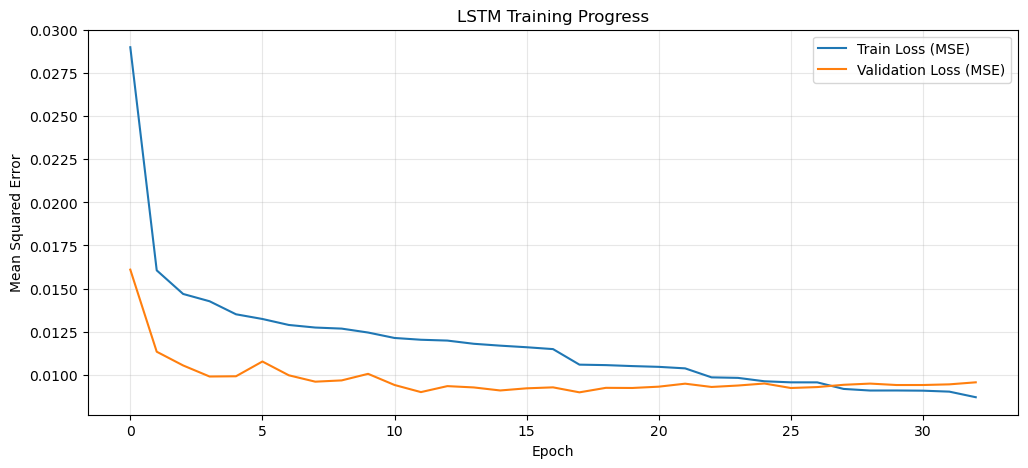

In [32]:

plt.figure(figsize=(12, 5))
plt.plot(history.history['loss'], label='Train Loss (MSE)')
plt.plot(history.history['val_loss'], label='Validation Loss (MSE)')
plt.title('LSTM Training Progress')
plt.ylabel('Mean Squared Error')
plt.xlabel('Epoch')
plt.legend()
plt.grid(True, alpha=0.3)
plt.savefig(LSTM_FIGURE_DIR / 'training_loss.png', dpi=160, bbox_inches='tight')
plt.show()

Features used: 13 (Should be 13)
Sensor List: ['s_2', 's_3', 's_4', 's_7', 's_8', 's_11', 's_12', 's_13', 's_14', 's_15', 's_17', 's_20', 's_21']
Test Sequences Generated: (100, 30, 13) (Must be 100, 30, 13)
Predicting on Test Set...
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step

--- FINAL TEST SET SCORE ---
Test RMSE: 13.36 cycles


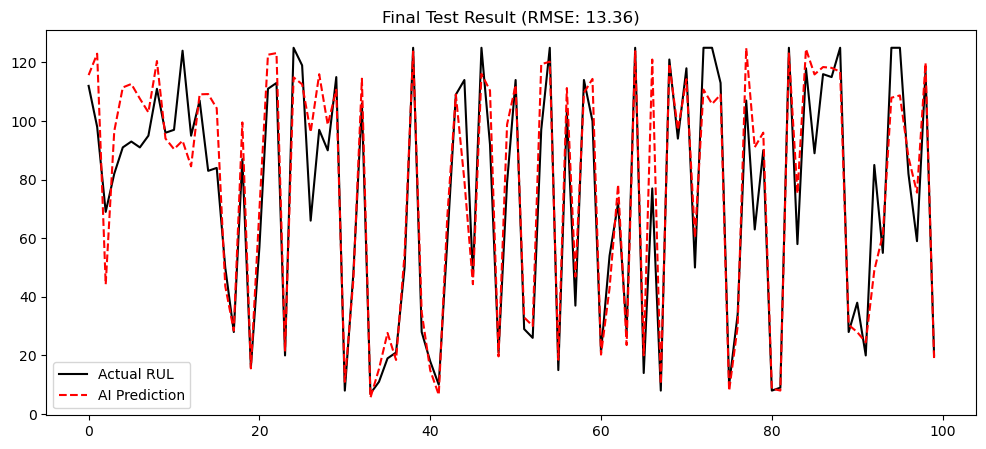

In [36]:
from sklearn.metrics import mean_squared_error


train_df = pd.read_csv(RAW_DATA_DIR / 'train_FD001.txt', sep=r'\s+', header=None)
test_df = pd.read_csv(RAW_DATA_DIR / 'test_FD001.txt', sep=r'\s+', header=None)
truth_df = pd.read_csv(RAW_DATA_DIR / 'RUL_FD001.txt', sep=r'\s+', header=None)


cols = ['unit_nr', 'time_cycles', 'setting_1', 'setting_2', 'setting_3'] + ['s_{}'.format(i) for i in range(1, 22)]
train_df.columns = cols
test_df.columns = cols


drop_cols = ['setting_1', 'setting_2', 'setting_3', 
             's_1', 's_5', 's_6', 's_9', 's_10', 's_16', 's_18', 's_19']

train_df = train_df.drop(drop_cols, axis=1)
test_df = test_df.drop(drop_cols, axis=1)


sensors = [c for c in train_df.columns if 's_' in c]
print(f"Features used: {len(sensors)} (Should be 13)")
print(f"Sensor List: {sensors}")

# Reuse the scaler fitted ONLY on training engines during preparation.
assert sensors == preparation['sensor_names']
scaler = joblib.load(prepared_dir / 'scaler.pkl')
test_df[sensors] = scaler.transform(test_df[sensors])


sequence_length = 30
X_test = []
valid_ids = []

for unit_id in test_df['unit_nr'].unique():
    unit_data = test_df[test_df['unit_nr'] == unit_id]
    
    if len(unit_data) >= sequence_length:
        seq = unit_data[sensors].values[-sequence_length:]
        X_test.append(seq)
        valid_ids.append(unit_id)

X_test = np.array(X_test)
print(f"Test Sequences Generated: {X_test.shape} (Must be 100, 30, 13)")


print("Predicting on Test Set...")
y_pred_scaled = model.predict(X_test)


MAX_RUL = 125.0
y_pred_cycles = y_pred_scaled * MAX_RUL
y_pred_cycles = np.clip(y_pred_cycles, 0, MAX_RUL)


y_true = truth_df.iloc[[x-1 for x in valid_ids]][0].values
y_true_clipped = np.clip(y_true, 0, MAX_RUL)

rmse = np.sqrt(mean_squared_error(y_true_clipped, y_pred_cycles))

print(f"\n--- FINAL TEST SET SCORE ---")
print(f"Test RMSE: {rmse:.2f} cycles")


plt.figure(figsize=(12, 5))
plt.plot(y_true_clipped, label='Actual RUL', color='black')
plt.plot(y_pred_cycles, label='AI Prediction', color='red', linestyle='--')
plt.title(f'Final Test Result (RMSE: {rmse:.2f})')
plt.legend()
plt.savefig(LSTM_FIGURE_DIR / 'test_predictions.png', dpi=160, bbox_inches='tight')
plt.show()

In [37]:
from sklearn.metrics import r2_score

# Calculate R²
r2 = r2_score(y_true_clipped, y_pred_cycles)

print(f"--- DETAILED METRICS ---")
print(f"RMSE: {rmse:.2f} cycles")
print(f"R² Score: {r2:.4f}")

--- DETAILED METRICS ---
RMSE: 13.36 cycles
R² Score: 0.8888


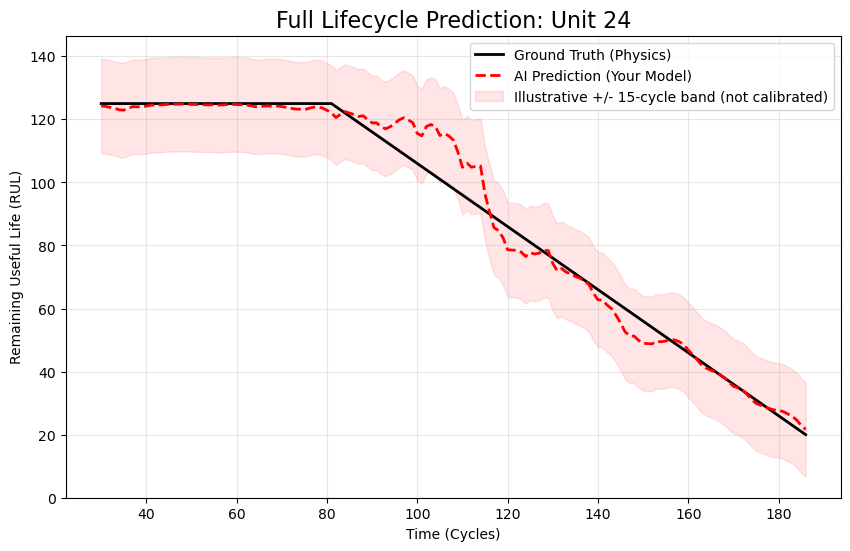

In [38]:
import matplotlib.pyplot as plt

# Let's pick a specific engine from the TEST set (e.g., Unit 24)
unit_id_to_plot = 24

# 1. Get data for this unit
unit_data = test_df[test_df['unit_nr'] == unit_id_to_plot]
sensors = [c for c in train_df.columns if 's_' in c]

# 2. We need to predict RUL for EVERY moment in this engine's life, not just the last one
# We slide the window across the whole timeline
X_life = []
indices = []

for i in range(sequence_length, len(unit_data) + 1):
    seq = unit_data[sensors].values[i-sequence_length:i]
    X_life.append(seq)
    indices.append(i)

X_life = np.array(X_life)

# 3. Predict the whole lifecycle
y_life_pred_scaled = model.predict(X_life, verbose=0)
y_life_pred = y_life_pred_scaled.flatten() * 125.0
y_life_pred = np.clip(y_life_pred, 0, 125.0)

# 4. Create the "True" RUL line
# We know the final true RUL from the truth file
final_true_rul = truth_df.iloc[unit_id_to_plot-1][0]
# The RUL at any point 't' is: Final_True + (Total_Len - t)
total_cycles = len(unit_data)
time_axis = np.arange(sequence_length, total_cycles + 1)
true_rul_curve = [final_true_rul + (total_cycles - t) for t in time_axis]
# Clip true RUL to 125 to match model training logic
true_rul_curve_clipped = np.clip(true_rul_curve, 0, 125.0)

# 5. Plot
plt.figure(figsize=(10, 6))
plt.plot(time_axis, true_rul_curve_clipped, label='Ground Truth (Physics)', color='black', linewidth=2)
plt.plot(time_axis, y_life_pred, label='AI Prediction (Your Model)', color='red', linewidth=2, linestyle='--')
plt.fill_between(time_axis, y_life_pred - 15, y_life_pred + 15, color='red', alpha=0.1, label='Illustrative +/- 15-cycle band (not calibrated)')

plt.title(f'Full Lifecycle Prediction: Unit {unit_id_to_plot}', fontsize=16)
plt.xlabel('Time (Cycles)')
plt.ylabel('Remaining Useful Life (RUL)')
plt.legend()
plt.grid(True, alpha=0.3)
plt.savefig(LSTM_FIGURE_DIR / f'engine{unit_id_to_plot}_lifecycle.png', dpi=160, bbox_inches='tight')
plt.show()

In [39]:
# Save the retrained model together with its matching preprocessing artifacts.
model.save(model_dir / 'model.keras')
joblib.dump(scaler, model_dir / 'scaler.pkl')
(model_dir / 'metadata.json').write_text(json.dumps(preparation, indent=2), encoding='utf-8')
metrics = {
    'validation_rmse_cycles': float(final_rmse),
    'test_rmse_cycles': float(rmse), 'test_r2': float(r2),
    'epochs_completed': len(history.history['loss']),
    'best_epoch': int(np.argmin(history.history['val_loss']) + 1),
}
(model_dir / 'metrics.json').write_text(json.dumps(metrics, indent=2), encoding='utf-8')
(model_dir / 'history.json').write_text(
    json.dumps({k: [float(v) for v in values] for k, values in history.history.items()}, indent=2),
    encoding='utf-8'
)
print(f"Corrected model, scaler, split metadata, metrics and history saved to {model_dir}")

Corrected model, scaler, split metadata, metrics and history saved to saved_models\lstm_fd001_v2


In [40]:
# Inspect the training-only arrays loaded in the data-loading cell; do not reload legacy arrays.

print("--- DIAGNOSTIC REPORT ---")

# CHECK 1: SHAPES
print(f"1. X Shape: {X_train.shape} (Should be N, 30, 13)")
print(f"2. y Shape: {y_train.shape} (Should be N, 1)")

# CHECK 2: DATA RANGES (Crucial for Neural Networks)
print(f"3. X Range: Min={X_train.min():.4f}, Max={X_train.max():.4f}")
print(f"4. y Range: Min={y_train.min():.4f}, Max={y_train.max():.4f}")

# CHECK 3: SAMPLE TARGETS
# We want to see if the RUL actually counts down or if it's shuffled/random
print("\n5. First 10 Target Values (Raw RUL; clipping to 125 happens in the training cell):")
print(y_train[:10].flatten())

# CHECK 4: ALIGNMENT CHECK
# We check if the last step of the input window matches the physics of the target
# Contribution direction depends on the sensor; one pair does not verify alignment.
print("\n6. Input vs Target Sample (Index 0):")
print(f"   Input (Last Step of Sensor 11): {X_train[0, -1, sensors.index('s_11')]:.4f}") # Select sensor 11 by name
print(f"   Target RUL: {y_train[0][0]}")

# CHECK 5: VARIANCE
# If variance is 0, your model has nothing to learn
print(f"\n7. y Variance: {np.var(y_train):.2f}")

--- DIAGNOSTIC REPORT ---
1. X Shape: (14241, 30, 13) (Should be N, 30, 13)
2. y Shape: (14241, 1) (Should be N, 1)
3. X Range: Min=0.0000, Max=1.0000
4. y Range: Min=0.0000, Max=332.0000

5. First 10 Target Values (Raw RUL; clipping to 125 happens in the training cell):
[257. 256. 255. 254. 253. 252. 251. 250. 249. 248.]

6. Input vs Target Sample (Index 0):
   Input (Last Step of Sensor 11): 0.2096
   Target RUL: 257.0

7. y Variance: 3940.57


In [41]:
import shap

SHAP explains the newly trained model's predictions using only training-engine
windows as the background. Run the corrected data-loading, training and test
evaluation cells first. Do not combine the previous saved model with the new scaler.

Previous model metrics and SHAP outputs are preserved in the archive/pre_reorganization_sources.zip.
The code below uses approximate expected gradients; its explanation gap is not
prediction error against true RUL.

Explaining 30 engines. This may take a few minutes...


c:\Users\Zohair\anaconda3\envs\exam_env\Lib\site-packages\keras\src\models\functional.py:241: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: keras_tensor_21
Received: inputs=['Tensor(shape=(30, 30, 13))']
  warnings.warn(msg)
c:\Users\Zohair\anaconda3\envs\exam_env\Lib\site-packages\keras\src\models\functional.py:241: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: keras_tensor_21
Received: inputs=['Tensor(shape=(50, 30, 13))']
  warnings.warn(msg)


Background mean prediction: 80.89 cycles
Mean absolute explanation gap: 1.82 cycles
Maximum absolute explanation gap: 5.72 cycles


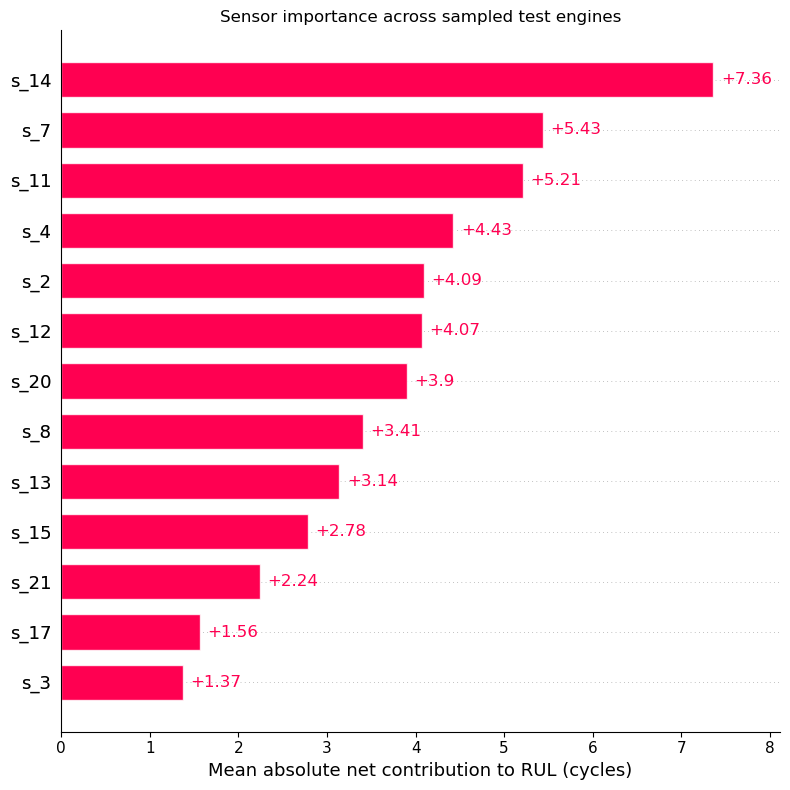


Engine: 55
Model prediction: 120.25 cycles
Explanation gap: -0.05 cycles


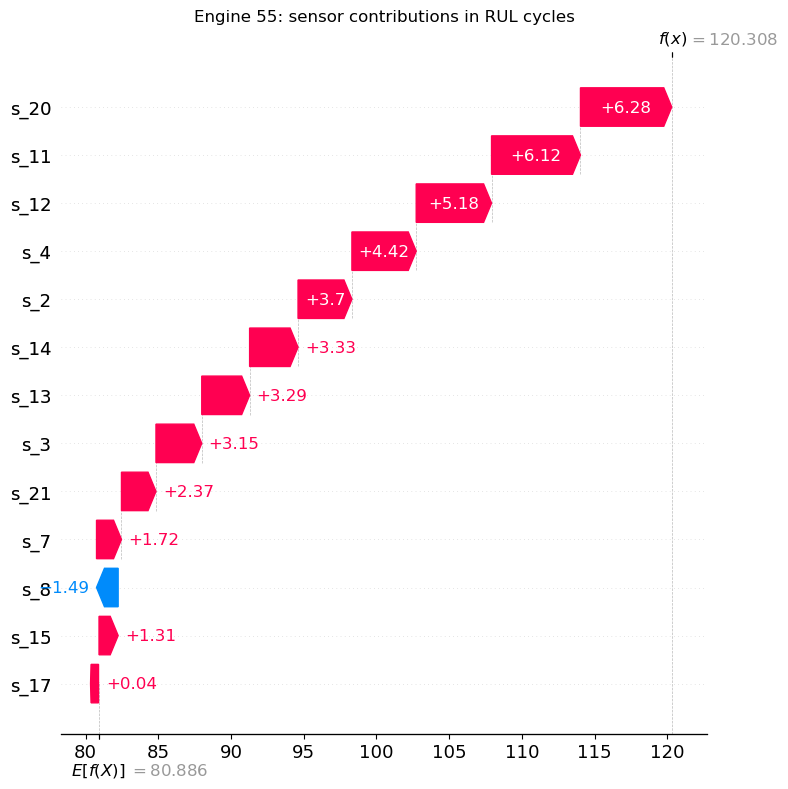

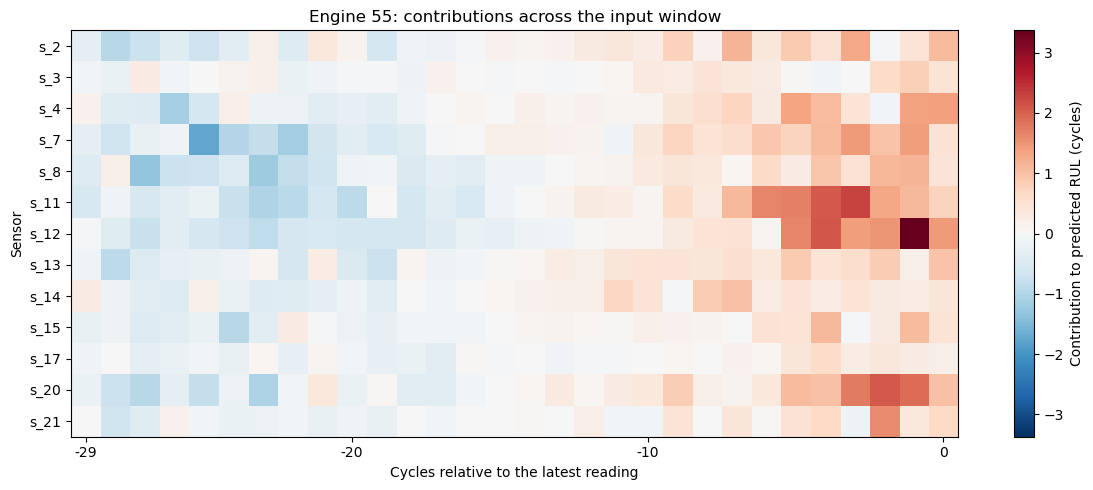

In [42]:
# 1. SETTINGS
MAX_RUL = 125.0
SEED = 42

sensor_names = [
    's_2', 's_3', 's_4', 's_7', 's_8', 's_11', 's_12',
    's_13', 's_14', 's_15', 's_17', 's_20', 's_21'
]

rng = np.random.default_rng(SEED)

# X_train already contains only training engines; validation engines are separate.
training_pool = X_train

background_indices = rng.choice(
    len(training_pool), size=min(100, len(training_pool)), replace=False
)
background = training_pool[background_indices].astype(np.float32)

# Explain a reproducible sample of test engines.
test_indices = rng.choice(
    len(X_test), size=min(30, len(X_test)), replace=False
)
X_explain = X_test[test_indices].astype(np.float32)
engine_ids = np.asarray(valid_ids)[test_indices]

assert X_explain.shape[1:] == (30, 13)
assert background.shape[1:] == (30, 13)

# 2. COMPUTE APPROXIMATE SHAP VALUES
print(f"Explaining {len(X_explain)} engines. This may take a few minutes...")

explainer = shap.GradientExplainer(model, background)

raw_values = explainer.shap_values(
    X_explain,
    nsamples=500,
    rseed=SEED
)

# Handle SHAP versions that return a list or an extra output dimension.
if isinstance(raw_values, list):
    if len(raw_values) != 1:
        raise ValueError("Expected a model with one output.")
    raw_values = raw_values[0]

shap_values = np.asarray(raw_values)

if shap_values.ndim == 4 and shap_values.shape[-1] == 1:
    shap_values = shap_values[..., 0]

if shap_values.shape != X_explain.shape:
    raise ValueError(f"Unexpected SHAP shape: {shap_values.shape}")

# Model output is scaled to 0–1; convert contributions to RUL cycles.
shap_cycles = shap_values * MAX_RUL

# SUM signed contributions across time to preserve their total.
sensor_contributions = shap_cycles.sum(axis=1)

baseline_cycles = float(
    np.asarray(model.predict(background, verbose=0)).mean() * MAX_RUL
)
predicted_cycles = (
    np.asarray(model.predict(X_explain, verbose=0)).reshape(-1) * MAX_RUL
)

# Expected gradients is approximate, so check reconstruction error.
reconstructed_cycles = baseline_cycles + sensor_contributions.sum(axis=1)
residuals = predicted_cycles - reconstructed_cycles

print(f"Background mean prediction: {baseline_cycles:.2f} cycles")
print(f"Mean absolute explanation gap: {np.abs(residuals).mean():.2f} cycles")
print(f"Maximum absolute explanation gap: {np.abs(residuals).max():.2f} cycles")

# 3. GLOBAL IMPORTANCE: which sensors matter across sampled engines?
global_explanation = shap.Explanation(
    values=sensor_contributions,
    base_values=np.full(len(X_explain), baseline_cycles),
    feature_names=sensor_names
)

shap.plots.bar(global_explanation, max_display=13, show=False)
plt.title("Sensor importance across sampled test engines")
plt.xlabel("Mean absolute net contribution to RUL (cycles)")
plt.tight_layout()
plt.savefig(LSTM_FIGURE_DIR / 'shap_sensor_importance.png', dpi=160, bbox_inches='tight')
plt.show()

# 4. LOCAL EXPLANATION: why this engine received its prediction
example_index = 0  # Change this to inspect another sampled engine.
engine_id = engine_ids[example_index]

print(f"\nEngine: {engine_id}")
print(f"Model prediction: {predicted_cycles[example_index]:.2f} cycles")
print(f"Explanation gap: {residuals[example_index]:+.2f} cycles")

local_explanation = shap.Explanation(
    values=sensor_contributions[example_index],
    base_values=baseline_cycles,
    feature_names=sensor_names
)

shap.plots.waterfall(local_explanation, max_display=13, show=False)
plt.title(f"Engine {engine_id}: sensor contributions in RUL cycles")
plt.tight_layout()
plt.savefig(LSTM_FIGURE_DIR / f'shap_engine{engine_id}_waterfall.png', dpi=160, bbox_inches='tight')
plt.show()

# 5. TIME VIEW: which readings within the 30-cycle window matter?
heatmap = shap_cycles[example_index].T
limit = max(float(np.abs(heatmap).max()), 1e-8)

fig, ax = plt.subplots(figsize=(12, 5))
im = ax.imshow(
    heatmap,
    aspect="auto",
    cmap="RdBu_r",
    vmin=-limit,
    vmax=limit
)

ax.set_yticks(np.arange(len(sensor_names)))
ax.set_yticklabels(sensor_names)
ax.set_xticks([0, 9, 19, 29])
ax.set_xticklabels(["-29", "-20", "-10", "0"])
ax.set_xlabel("Cycles relative to the latest reading")
ax.set_ylabel("Sensor")
ax.set_title(f"Engine {engine_id}: contributions across the input window")

fig.colorbar(im, ax=ax, label="Contribution to predicted RUL (cycles)")
plt.tight_layout()
plt.savefig(LSTM_FIGURE_DIR / f'shap_engine{engine_id}_heatmap.png', dpi=160, bbox_inches='tight')
plt.show()